## 0. Setup: environment and ground truth

In [1]:
import heapq
import itertools
import random
import time

import numpy as np
from scipy.optimize import linprog
import mo_gymnasium as mo_gym

np.set_printoptions(suppress=True, precision=3)

env = mo_gym.make("deep-sea-treasure-v0")
core = env.unwrapped
GAMMA = 0.99
N_ACTIONS = core.action_space.n
FEAT_DIM = 2
START_STATE = (0, 0)

ground_truth_ccs = np.array(core.pareto_front(gamma=GAMMA))
print(f"{N_ACTIONS} actions, {FEAT_DIM} objectives, ground-truth CCS has {len(ground_truth_ccs)} points.")

4 actions, 2 objectives, ground-truth CCS has 10 points.


/opt/anaconda3/envs/okb/lib/python3.10/site-packages/gymnasium/spaces/box.py:297: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(


## 1. Successor features, the OLS building blocks, and the exact model

In [2]:
class SFTable:
    def __init__(self, num_actions, feat_dim, default_vec):
        self.default_vec = default_vec 
        self.table = {}

    def __getitem__(self, state):
        if state not in self.table:
            self.table[state] = self.default_vec.copy()
        return self.table[state]

def expected_sf(psi_table, w, start_state=START_STATE):
    values = psi_table[start_state] @ w
    return psi_table[start_state][np.argmax(values)].copy()

In [3]:
def v_smp(psi_vecs, w):
    if not psi_vecs:
        return -np.inf
    return max(v @ w for v in psi_vecs)


def corner_weights_2d(psi_vecs, n_grid=2000):
    w0_grid = np.linspace(0.0, 1.0, n_grid)
    weights = np.stack([w0_grid, 1 - w0_grid], axis=1)
    values_per_policy = weights @ np.array(psi_vecs).T
    best_policy = values_per_policy.argmax(axis=1)
    switch_idx = np.where(np.diff(best_policy) != 0)[0]
    return [np.array([w0, 1 - w0]) for w0 in w0_grid[switch_idx]]

# quick check: 2 policies (the segment endpoints) should give exactly 1 corner weight
demo_psi = [ground_truth_ccs[0], ground_truth_ccs[-1]]
print("Corner weight between the cheapest and priciest treasure:", corner_weights_2d(demo_psi))

Corner weight between the cheapest and priciest treasure: [array([0.462, 0.538])]


In [4]:
def estimate_improvement(w, psi_vecs, w_exp):
    """Delta(w) = v_bar*_w - v^SMP_w, via the LP in Algorithm 2."""
    if not w_exp:
        return np.inf  # nothing constrains the bound yet -> unbounded potential
    d = len(w)
    A_ub = np.array([w_prime for w_prime in w_exp])
    b_ub = np.array([v_smp(psi_vecs, w_prime) for w_prime in w_exp])
    res = linprog(c=-np.array(w), A_ub=A_ub, b_ub=b_ub, bounds=[(None, None)] * d, method="highs")
    v_bar = -res.fun if res.success else np.inf
    return v_bar - v_smp(psi_vecs, w)


# sanity check: with only the two segment endpoints solved, the improvement estimate
# at their exact corner weight should be strictly positive (there's a real gap to close)
w_corner = corner_weights_2d(demo_psi)[0]
print("Delta at the one corner weight:", estimate_improvement(w_corner, demo_psi, [np.array([1.0, 0.0]), np.array([0.0, 1.0])]))

Delta at the one corner weight: 8.808890436766786


In [5]:
def step_deterministic(s, a):
    ns = (s[0] + int(core.dir[a][0]), s[1] + int(core.dir[a][1]))
    if not (0 <= ns[0] <= 10 and 0 <= ns[1] <= 10) or core.sea_map[ns] == -10:
        ns = s
    treasure = core.sea_map[ns]
    terminal = treasure != 0 and treasure != -10
    phi = np.array([treasure if terminal else 0.0, -1.0])
    return ns, phi, terminal


nrows, ncols = core.sea_map.shape
states = [(r, c) for r in range(nrows) for c in range(ncols) if core.sea_map[r, c] != -10]
is_terminal = {s: core.sea_map[s] != 0 for s in states}
state_idx = {s: i for i, s in enumerate(states)}
n_states = len(states)
nonterminal = [s for s in states if not is_terminal[s]]


def policy_iteration(w, gamma=GAMMA):
    policy = {s: 0 for s in states if not is_terminal[s]}
    while True:
        A, b = np.eye(n_states), np.zeros(n_states)
        for s in states:
            if is_terminal[s]:
                continue
            i = state_idx[s]
            ns, phi, term = step_deterministic(s, policy[s])
            b[i] = phi @ w
            if not term:
                A[i, state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[state_idx[s]] for s in states}

        stable = True
        for s in states:
            if is_terminal[s]:
                continue
            qs = []
            for a in range(N_ACTIONS):
                ns, phi, term = step_deterministic(s, a)
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_a = int(np.argmax(qs))
            stable &= best_a == policy[s]
            policy[s] = best_a
        if stable:
            return policy, V


def solve_task_exact(w, gamma=GAMMA):
    policy, _ = policy_iteration(w, gamma)
    A, b = np.eye(n_states), np.zeros((n_states, FEAT_DIM))
    for s in states:
        if is_terminal[s]:
            continue
        i = state_idx[s]
        ns, phi, term = step_deterministic(s, policy[s])
        b[i] = phi
        if not term:
            A[i, state_idx[ns]] -= gamma
    V = np.linalg.solve(A, b)
    V = {s: V[state_idx[s]] for s in states}

    psi = SFTable(N_ACTIONS, FEAT_DIM, np.zeros((N_ACTIONS, FEAT_DIM)))
    for s in states:
        if is_terminal[s]:
            continue
        table = np.zeros((N_ACTIONS, FEAT_DIM))
        for a in range(N_ACTIONS):
            ns, phi, term = step_deterministic(s, a)
            table[a] = phi if term else phi + gamma * V[ns]
        psi.table[s] = table
    return psi

### The two per-weight solvers

`solve_task_exact` (value/policy iteration, no TD/Q-learning) and `solve_task` (optimistic tabular Q-learning) both produce an `SFTable` for a single weight -- `solve_for_weight` dispatches between them via a `solver` flag so the CCS-computing algorithms below (`sfols_exact` for the standard baseline, `sfols_certified` for the basis + metapolicy) can each be run with either one.

In [6]:
def gpi_action(rng, state, w, sf_tables):
    """argmax_a max_i psi_i(state, a) . w, breaking ties uniformly at random."""
    values = np.stack([sft[state] @ w for sft in sf_tables], axis=0)  # (n_tables, A)
    action_values = values.max(axis=0)  # (A,) -- best over tables, per action
    max_val = action_values.max()
    candidates = np.flatnonzero(np.isclose(action_values, max_val))
    return int(rng.choice(candidates))


def solve_task(env, w, num_steps=100_000, alpha=0.1, gamma=GAMMA,
               eps_start=1.0, eps_end=0.05, optimistic_vec=(25.0, 0.0), seed=0):
    """Learn a tabular SF psi(s,a) for a single scalarized task r.w, via optimistic
    tabular TD-learning (Q-learning) -- the paper's other per-weight solver.
    optimistic_vec must upper-bound the true SF in every component so unvisited
    (state, action) pairs always look promising."""
    rng = random.Random(seed)
    default_vec = np.tile(np.array(optimistic_vec), (N_ACTIONS, 1))
    psi = SFTable(N_ACTIONS, FEAT_DIM, default_vec)

    obs, _ = env.reset(seed=seed)
    state = tuple(int(x) for x in obs)
    for t in range(num_steps):
        eps = max(eps_end, eps_start - (eps_start - eps_end) * t / num_steps)
        if rng.random() < eps:
            action = rng.randrange(N_ACTIONS)
        else:
            action = gpi_action(rng, state, w, [psi])

        next_obs, phi, terminated, truncated, _ = env.step(action)
        next_state = tuple(int(x) for x in next_obs)
        if terminated:
            target = phi
        else:
            a_prime = gpi_action(rng, next_state, w, [psi])
            target = phi + gamma * psi[next_state][a_prime]
        psi[state][action] += alpha * (target - psi[state][action])

        if terminated or truncated:
            obs, _ = env.reset()
            state = tuple(int(x) for x in obs)
        else:
            state = next_state
    return psi


def solve_for_weight(w, solver="exact", num_steps=100_000, seed=0):
    """Dispatch a single per-weight solve to either the exact solver or Q-learning.
    Used everywhere a per-weight solve is needed: the standard baseline (Part 1) and
    the basis's own solves (Part 2 -- both the initial canonical corners and any
    Certify-or-Grow fallback). Q-learning here is genuinely noisy: even when a base
    policy it produces is imperfect, the Bellman certificate still checks against the
    exact known dynamics, so correctness never depends on solver quality -- a worse
    solve just costs more fallback solves, it can't silently certify a wrong answer."""
    if solver == "exact":
        return solve_task_exact(w)
    elif solver == "q_learning":
        return solve_task(env, w, num_steps=num_steps, seed=seed)
    raise ValueError(f"solver must be 'exact' or 'q_learning', got {solver!r}")

## Part 1 -- Standard SFOLS: computing the CCS with independent exact solves


In [7]:
def sfols_exact(num_objectives=2, max_iterations=25, tol=1e-2, verbose=True,
                 solver="exact", num_steps=100_000, seed=0):
    Psi, Pi, W_exp = [], [], []
    counter = itertools.count()
    Q = []
    for i in range(num_objectives):
        w = np.zeros(num_objectives)
        w[i] = 1.0
        heapq.heappush(Q, (-np.inf, next(counter), tuple(w)))

    history = []
    n_solves = 0
    it = 0
    while Q and it < max_iterations:
        neg_priority, _, w_tuple = heapq.heappop(Q)
        priority = -neg_priority
        if priority < tol and Psi:
            break
        w = np.array(w_tuple)
        it += 1

        psi_table = solve_for_weight(w, solver=solver, num_steps=num_steps, seed=seed + it)
        n_solves += 1
        psi_vec = expected_sf(psi_table, w)
        W_exp.append(w)
        is_new = not any(np.allclose(psi_vec, v, atol=1e-1) for v in Psi)

        if verbose:
            print(f"iter {it:2d}  w={w.round(3)}  priority={priority:8.4f}  psi={psi_vec.round(3)}  new={is_new}")

        if is_new:
            kept, removed = [], []
            for (p, c, wt) in Q:
                if p == -np.inf or not (psi_vec @ np.array(wt) > v_smp(Psi, np.array(wt)) + 1e-9):
                    kept.append((p, c, wt))
                else:
                    removed.append(wt)
            Q = kept
            heapq.heapify(Q)

            corners = corner_weights_2d(Psi + [psi_vec]) if Psi else []
            Psi.append(psi_vec)
            Pi.append(psi_table)

            for wc in corners:
                delta = estimate_improvement(wc, Psi, W_exp)
                heapq.heappush(Q, (-delta, next(counter), tuple(wc)))

        history.append((it, len(Psi), priority))

    return Pi, Psi, W_exp, history, n_solves


t0 = time.perf_counter()
Pi_exact, Psi_exact, W_exp_exact, history_exact, n_solves_exact = sfols_exact(max_iterations=25, tol=1e-2, verbose=True)
t_exact_single = time.perf_counter() - t0

print(f"\nstandard CCS discovery (exact policy iteration, NO basis reuse): {t_exact_single*1000:.1f} ms, "
      f"{len(history_exact)} iterations, {n_solves_exact} full from-scratch solves, "
      f"{len(Psi_exact)} points found")

Psi_exact_arr = np.array(Psi_exact)
all_matched_exact = all(np.min(np.linalg.norm(Psi_exact_arr - gt, axis=1)) < 1e-6 for gt in ground_truth_ccs)
print(f"all {len(ground_truth_ccs)} ground-truth CCS points recovered exactly: {all_matched_exact}")

iter  1  w=[1. 0.]  priority=     inf  psi=[ 19.778 -17.383]  new=True
iter  2  w=[0. 1.]  priority=     inf  psi=[ 0.7 -1. ]  new=True
iter  3  w=[0.462 0.538]  priority=  8.8089  psi=[11.047 -4.901]  new=True
iter  4  w=[0.588 0.412]  priority=  2.0529  psi=[14.856 -8.648]  new=True
iter  5  w=[0.274 0.726]  priority=  1.5869  psi=[ 8.037 -2.97 ]  new=True
iter  6  w=[0.639 0.361]  priority=  0.6100  psi=[ 17.373 -12.248]  new=True


iter  7  w=[0.212 0.788]  priority=  0.4459  psi=[ 0.7 -1. ]  new=False
iter  8  w=[0.212 0.788]  priority=  0.4459  psi=[ 0.7 -1. ]  new=False
iter  9  w=[0.681 0.319]  priority=  0.2768  psi=[ 19.073 -15.706]  new=True


iter 10  w=[0.391 0.609]  priority=  0.2181  psi=[ 8.037 -2.97 ]  new=False


iter 11  w=[0.391 0.609]  priority=  0.2181  psi=[ 8.037 -2.97 ]  new=False
iter 12  w=[0.391 0.609]  priority=  0.2181  psi=[ 8.037 -2.97 ]  new=False
iter 13  w=[0.496 0.504]  priority=  0.1877  psi=[13.181 -6.793]  new=True
iter 14  w=[0.525 0.475]  priority=  0.0708  psi=[14.074 -7.726]  new=True
iter 15  w=[0.704 0.296]  priority=  0.0509  psi=[ 19.073 -15.706]  new=False
iter 16  w=[0.704 0.296]  priority=  0.0509  psi=[ 19.073 -15.706]  new=False
iter 17  w=[0.704 0.296]  priority=  0.0509  psi=[ 19.073 -15.706]  new=False
iter 18  w=[0.67 0.33]  priority=  0.0400  psi=[ 17.814 -13.125]  new=True


iter 19  w=[0.47 0.53]  priority=  0.0244  psi=[11.047 -4.901]  new=False
iter 20  w=[0.47 0.53]  priority=  0.0244  psi=[11.047 -4.901]  new=False


iter 21  w=[0.47 0.53]  priority=  0.0244  psi=[11.047 -4.901]  new=False


iter 22  w=[0.541 0.459]  priority=  0.0204  psi=[14.074 -7.726]  new=False
iter 23  w=[0.541 0.459]  priority=  0.0204  psi=[14.074 -7.726]  new=False
iter 24  w=[0.51 0.49]  priority=  0.0132  psi=[13.181 -6.793]  new=False
iter 25  w=[0.51 0.49]  priority=  0.0132  psi=[13.181 -6.793]  new=False

standard CCS discovery (exact policy iteration, NO basis reuse): 523.0 ms, 25 iterations, 25 full from-scratch solves, 10 points found
all 10 ground-truth CCS points recovered exactly: True


In [8]:
# same algorithm, but each per-weight solve is now Q-learning instead of value
# iteration -- num_steps kept modest here (this is a demo, not the paper's own
# 100k-step budget) since 25 iterations x a from-scratch Q-learning run adds up.
t0 = time.perf_counter()
Pi_exact_ql, Psi_exact_ql, W_exp_exact_ql, history_exact_ql, n_solves_exact_ql = sfols_exact(
    max_iterations=25, tol=1e-2, verbose=False, solver="q_learning", num_steps=20_000, seed=0)
t_exact_ql = time.perf_counter() - t0

print(f"standard CCS discovery (Q-learning, NO basis reuse): {t_exact_ql*1000:.1f} ms, "
      f"{len(history_exact_ql)} iterations, {n_solves_exact_ql} full from-scratch solves, "
      f"{len(Psi_exact_ql)} points found")

# Q-learning is noisy, so match within a looser tolerance than the exact solver's 1e-6
Psi_exact_ql_arr = np.array(Psi_exact_ql)
all_matched_ql = all(np.min(np.linalg.norm(Psi_exact_ql_arr - gt, axis=1)) < 0.5 for gt in ground_truth_ccs)
print(f"all {len(ground_truth_ccs)} ground-truth CCS points recovered (within Q-learning tolerance 0.5): {all_matched_ql}")

standard CCS discovery (Q-learning, NO basis reuse): 10512.6 ms, 5 iterations, 5 full from-scratch solves, 3 points found
all 10 ground-truth CCS points recovered (within Q-learning tolerance 0.5): False


## Part 2 -- Certified/adaptive SFOLS: basis policies and the metapolicy

In [9]:
def own_greedy_actions(sf_table, w):
    return {s: int(np.argmax(sf_table[s] @ w)) for s in states if not is_terminal[s]}

In [10]:
def meta_policy_iteration_warm(w, Pi_base, W_base, gamma=GAMMA, gpi_init=True, max_sweeps=500):
    """max_sweeps is a safety cap, not a tuning knob: with EXACT base policies this
    loop always reaches a stable fixed point in a handful of sweeps (standard policy
    iteration theory -- finite deterministic policies, monotonic improvement). With
    Q-learning-based bases the own_actions/values feeding it are noisy, and near-ties
    between two base policies can make the greedy improvement step cycle between them
    forever instead of stabilizing. If the cap is hit, we return the current
    (possibly non-fixed-point) meta_policy/V as a best-effort result -- correctness
    downstream is preserved because sfols_certified's Bellman certificate checks
    whatever V comes back against the TRUE exact dynamics regardless of whether it's
    a genuine fixed point, so a capped-out V just means the certificate correctly
    reports a nonzero gap and falls back to a real solve, instead of an infinite loop."""
    own_actions = [own_greedy_actions(sft, w_j) for sft, w_j in zip(Pi_base, W_base)]
    if gpi_init:
        meta_policy = {}
        for s in nonterminal:
            vals = [Pi_base[j][s][own_actions[j][s]] @ w for j in range(len(Pi_base))]
            meta_policy[s] = int(np.argmax(vals))
    else:
        meta_policy = {s: 0 for s in nonterminal}

    n_sweeps = 0
    while True:
        n_sweeps += 1
        A, b = np.eye(n_states), np.zeros(n_states)
        for s in nonterminal:
            i = state_idx[s]
            ns, phi, term = step_deterministic(s, own_actions[meta_policy[s]][s])
            b[i] = phi @ w
            if not term:
                A[i, state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[state_idx[s]] for s in states}
        stable = True
        for s in nonterminal:
            qs = []
            for j in range(len(Pi_base)):
                ns, phi, term = step_deterministic(s, own_actions[j][s])
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_j = int(np.argmax(qs))
            stable &= best_j == meta_policy[s]
            meta_policy[s] = best_j
        if stable or n_sweeps >= max_sweeps:
            return meta_policy, V, own_actions, n_sweeps


def meta_policy_sf(meta_policy, own_actions, gamma=GAMMA):
    A, b = np.eye(n_states), np.zeros((n_states, FEAT_DIM))
    for s in nonterminal:
        i = state_idx[s]
        ns, phi, term = step_deterministic(s, own_actions[meta_policy[s]][s])
        b[i] = phi
        if not term:
            A[i, state_idx[ns]] -= gamma
    Psi_arr = np.linalg.solve(A, b)
    return {s: Psi_arr[state_idx[s]] for s in states}

In [11]:
def bellman_gap(w, V_meta, gamma=GAMMA):
    gaps = {}
    for s in nonterminal:
        qs = []
        for a in range(N_ACTIONS):
            ns, phi, term = step_deterministic(s, a)
            qs.append(phi @ w + (0.0 if term else gamma * V_meta[ns]))
        gaps[s] = max(qs) - V_meta[s]
    return gaps


def sfols_certified(num_objectives=2, max_iterations=25, tol=1e-2, cert_tol=1e-6, verbose=True,
                     solver="exact", num_steps=100_000, seed=0):
    Pi_base, W_base = [], []
    for i in range(num_objectives):
        w = np.zeros(num_objectives)
        w[i] = 1.0
        Pi_base.append(solve_for_weight(w, solver=solver, num_steps=num_steps, seed=seed + i))
        W_base.append(w)

    Psi, W_exp = [], []
    counter = itertools.count()
    Q = []
    for i in range(num_objectives):
        w = np.zeros(num_objectives)
        w[i] = 1.0
        heapq.heappush(Q, (-np.inf, next(counter), tuple(w)))

    history = []
    n_composed, n_fallback = 0, 0
    it = 0
    while Q and it < max_iterations:
        neg_priority, _, w_tuple = heapq.heappop(Q)
        priority = -neg_priority
        if priority < tol and Psi:
            break
        w = np.array(w_tuple)
        it += 1

        meta_policy, V_meta, own_actions, _ = meta_policy_iteration_warm(w, Pi_base, W_base)
        worst_gap = max(bellman_gap(w, V_meta).values())

        if worst_gap > cert_tol:
            n_fallback += 1
            psi_table = solve_for_weight(w, solver=solver, num_steps=num_steps, seed=seed + it)
            Pi_base.append(psi_table)
            W_base.append(w)
            own_w = own_greedy_actions(psi_table, w)
            psi_vec = psi_table[START_STATE][own_w[START_STATE]]
            status = f"FALLBACK (gap={worst_gap:.4f}) -- basis grew to {len(Pi_base)}"
        else:
            n_composed += 1
            psi_vec = meta_policy_sf(meta_policy, own_actions)[START_STATE]
            status = "composed"

        W_exp.append(w)
        is_new = not any(np.allclose(psi_vec, v, atol=1e-1) for v in Psi)

        if verbose:
            print(f"iter {it:2d}  w={w.round(3)}  priority={priority:8.4f}  psi={psi_vec.round(3)}  new={is_new}  [{status}]")

        if is_new:
            kept = []
            for (p, c, wt) in Q:
                if p == -np.inf or not (psi_vec @ np.array(wt) > v_smp(Psi, np.array(wt)) + 1e-9):
                    kept.append((p, c, wt))
            Q = kept
            heapq.heapify(Q)

            corners = corner_weights_2d(Psi + [psi_vec]) if Psi else []
            Psi.append(psi_vec)

            for wc in corners:
                delta = estimate_improvement(wc, Psi, W_exp)
                heapq.heappush(Q, (-delta, next(counter), tuple(wc)))

        history.append((it, len(Psi), priority))

    return Pi_base, W_base, Psi, W_exp, history, n_composed, n_fallback


Pi_base_c, W_base_c, Psi_c, W_exp_c, history_c, n_composed, n_fallback = sfols_certified(
    max_iterations=25, tol=1e-2, verbose=True)

print(f"\ndiscovered {len(Psi_c)} points (ground-truth CCS has {len(ground_truth_ccs)} points)")
print(f"final basis size: {len(Pi_base_c)}  (composed: {n_composed}, fallback exact solves: {n_fallback})")

Psi_c_arr = np.array(Psi_c)
all_matched = True
for gt in ground_truth_ccs:
    dists = np.linalg.norm(Psi_c_arr - gt, axis=1)
    best = dists.argmin()
    matched = dists[best] < 1e-6
    all_matched &= matched
print(f"all {len(ground_truth_ccs)} ground-truth CCS points recovered exactly: {all_matched}")

iter  1  w=[1. 0.]  priority=     inf  psi=[ 19.778 -17.383]  new=True  [composed]
iter  2  w=[0. 1.]  priority=     inf  psi=[ 0.7 -1. ]  new=True  [composed]
iter  3  w=[0.462 0.538]  priority=  8.8089  psi=[11.047 -4.901]  new=True  [composed]
iter  4  w=[0.588 0.412]  priority=  2.0529  psi=[14.856 -8.648]  new=True  [composed]
iter  5  w=[0.274 0.726]  priority=  1.5869  psi=[ 8.037 -2.97 ]  new=True  [composed]
iter  6  w=[0.639 0.361]  priority=  0.6100  psi=[ 17.373 -12.248]  new=True  [composed]
iter  7  w=[0.212 0.788]  priority=  0.4459  psi=[ 0.7 -1. ]  new=False  [composed]
iter  8  w=[0.212 0.788]  priority=  0.4459  psi=[ 0.7 -1. ]  new=False  [composed]
iter  9  w=[0.681 0.319]  priority=  0.2768  psi=[ 19.073 -15.706]  new=True  [composed]
iter 10  w=[0.391 0.609]  priority=  0.2181  psi=[ 8.037 -2.97 ]  new=False  [composed]
iter 11  w=[0.391 0.609]  priority=  0.2181  psi=[ 8.037 -2.97 ]  new=False  [composed]
iter 12  w=[0.391 0.609]  priority=  0.2181  psi=[ 8.037 

iter 19  w=[0.47 0.53]  priority=  0.0244  psi=[11.047 -4.901]  new=False  [composed]
iter 20  w=[0.47 0.53]  priority=  0.0244  psi=[11.047 -4.901]  new=False  [composed]
iter 21  w=[0.47 0.53]  priority=  0.0244  psi=[11.047 -4.901]  new=False  [composed]
iter 22  w=[0.541 0.459]  priority=  0.0204  psi=[14.074 -7.726]  new=False  [composed]
iter 23  w=[0.541 0.459]  priority=  0.0204  psi=[14.074 -7.726]  new=False  [composed]
iter 24  w=[0.51 0.49]  priority=  0.0132  psi=[13.181 -6.793]  new=False  [composed]
iter 25  w=[0.51 0.49]  priority=  0.0132  psi=[13.181 -6.793]  new=False  [composed]

discovered 10 points (ground-truth CCS has 10 points)
final basis size: 2  (composed: 25, fallback exact solves: 0)
all 10 ground-truth CCS points recovered exactly: True


In [12]:
# same Certify-or-Grow loop, but any policy the basis needs (canonical corners, or a
# fallback growth) is now solved via Q-learning instead of value iteration. The
# Bellman certificate is still computed exactly, so this stays correct regardless of
# how noisy the underlying policies are -- it can only mean more fallback solves.
Pi_base_c_ql, W_base_c_ql, Psi_c_ql, W_exp_c_ql, history_c_ql, n_composed_ql, n_fallback_ql = sfols_certified(
    max_iterations=25, tol=1e-2, verbose=False, solver="q_learning", num_steps=20_000, seed=0)

print(f"discovered {len(Psi_c_ql)} points (ground-truth CCS has {len(ground_truth_ccs)} points)")
print(f"final basis size: {len(Pi_base_c_ql)}  (composed: {n_composed_ql}, fallback Q-learning solves: {n_fallback_ql})")

Psi_c_ql_arr = np.array(Psi_c_ql)
all_matched_ql = all(np.min(np.linalg.norm(Psi_c_ql_arr - gt, axis=1)) < 0.5 for gt in ground_truth_ccs)
print(f"all {len(ground_truth_ccs)} ground-truth CCS points recovered (within Q-learning tolerance 0.5): {all_matched_ql}")

discovered 3 points (ground-truth CCS has 10 points)
final basis size: 7  (composed: 0, fallback Q-learning solves: 5)
all 10 ground-truth CCS points recovered (within Q-learning tolerance 0.5): False


## Part 3 -- Head-to-head: standard vs. certified/adaptive

Both sides exact (no TD/Q-learning), 5 timed repeats, minimum reported -- matching the paper's DST table.

In [13]:
N_REPEATS = 5

ts_exact = []
for _ in range(N_REPEATS):
    t0 = time.perf_counter()
    Pi_e, Psi_e, W_exp_e, hist_e, n_solves_e = sfols_exact(max_iterations=25, tol=1e-2, verbose=False)
    ts_exact.append(time.perf_counter() - t0)
t_exact = min(ts_exact)

ts_cert = []
for _ in range(N_REPEATS):
    t0 = time.perf_counter()
    Pi_base_c, W_base_c, Psi_c, W_exp_c, hist_c, n_comp_c, n_fb_c = sfols_certified(max_iterations=25, tol=1e-2, verbose=False)
    ts_cert.append(time.perf_counter() - t0)
t_cert = min(ts_cert)

sep = "=" * 70
print(sep)
print("BENCHMARK: standard SFOLS vs. adaptive base + warm-started meta-policy")
print(sep)
print(f"standard SFOLS (exact policy iteration, {n_solves_e} solves):        {t_exact*1000:8.1f} ms")
print(f"adaptive base ({len(Pi_base_c)} policies, {n_comp_c} composed, "
      f"{n_fb_c} fallback solves): {t_cert*1000:8.1f} ms")
print(f"speedup: {t_exact/t_cert:.2f}x")

Psi_e_arr, Psi_c_arr = np.array(Psi_e), np.array(Psi_c)
match_e = all(np.linalg.norm(Psi_e_arr - gt, axis=1).min() < 1e-6 for gt in ground_truth_ccs)
match_c = all(np.linalg.norm(Psi_c_arr - gt, axis=1).min() < 1e-6 for gt in ground_truth_ccs)
print(f"both recover all {len(ground_truth_ccs)} ground-truth CCS points exactly: "
      f"standard={match_e}, adaptive={match_c}")

BENCHMARK: standard SFOLS vs. adaptive base + warm-started meta-policy
standard SFOLS (exact policy iteration, 25 solves):           460.9 ms
adaptive base (2 policies, 25 composed, 0 fallback solves):    203.1 ms
speedup: 2.27x
both recover all 10 ground-truth CCS points exactly: standard=True, adaptive=True


## Part 4 -- Inspect the metapolicy for a query weight

w = [0.6 0.4]   (basis size = 2, 2 policy-iteration sweeps)
metapolicy SF at start state = [ 17.373 -12.248]   scalarized value = 5.525
true optimal value at start state (policy_iteration) = 5.525
Bellman certificate: max gap = 0.000000  -> OPTIMAL, composition alone suffices


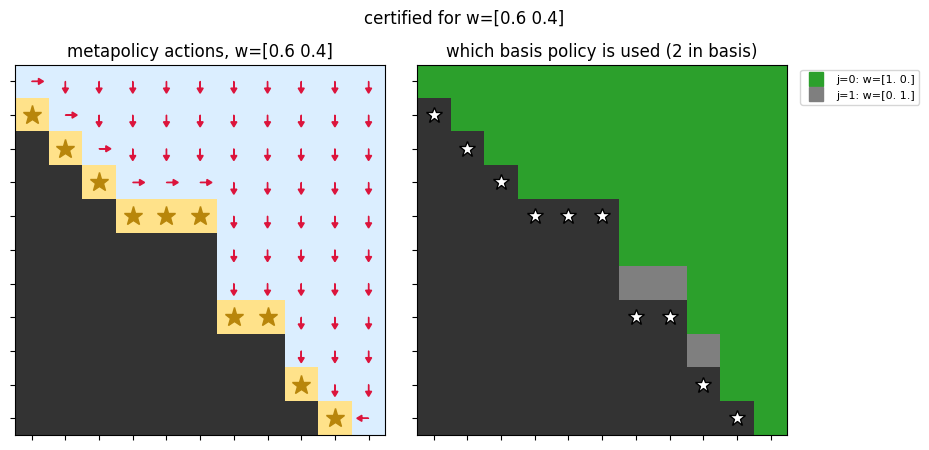

In [14]:
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt


def plot_arrows(ax, action_fn, sea_map, core, arrow_len=0.35):
    nrows, ncols = sea_map.shape
    cell_type = np.where(sea_map == -10, 0, np.where(sea_map > 0, 2, 1))
    cmap = ListedColormap(["#333333", "#dbeeff", "#ffe28a"])
    ax.imshow(cell_type, cmap=cmap, origin="upper", vmin=0, vmax=2)

    for r in range(nrows):
        for c in range(ncols):
            val = sea_map[r, c]
            if val == -10:
                continue
            if val > 0:
                ax.plot(c, r, marker="*", color="darkgoldenrod", markersize=14, zorder=3)
                continue
            action = action_fn((r, c))
            drow, dcol = core.dir[action]
            ax.arrow(c, r, dcol * arrow_len, drow * arrow_len, head_width=0.18, head_length=0.15,
                      fc="crimson", ec="crimson", length_includes_head=True, zorder=3)

    ax.set_xticks(range(ncols))
    ax.set_yticks(range(nrows))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_aspect("equal")


def plot_basis_choice(ax, meta_policy, W_base, sea_map):
    """Which base policy (by index into Pi_base/W_base) the metapolicy is deferring
    to at each state -- i.e. j*(s) from Definition 2, not the action itself."""
    nrows, ncols = sea_map.shape
    k = len(W_base)
    base_cmap = plt.get_cmap("tab10" if k <= 10 else "tab20")

    grid = np.full((nrows, ncols), np.nan)
    for (r, c), j in meta_policy.items():
        grid[r, c] = j

    cmap = base_cmap.copy()
    cmap.set_bad("#333333")  # rocks and terminal cells: not in meta_policy at all
    im = ax.imshow(np.ma.masked_invalid(grid), cmap=cmap, vmin=-0.5, vmax=k - 0.5, origin="upper")

    for r in range(nrows):
        for c in range(ncols):
            if sea_map[r, c] > 0:
                ax.plot(c, r, marker="*", color="white", markeredgecolor="black", markersize=12, zorder=3)

    ax.set_xticks(range(ncols))
    ax.set_yticks(range(nrows))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_aspect("equal")
    return im, cmap


# ---- set this to any weight you want to query ----
w_query = np.array([0.6, 0.4])

meta_policy, V_meta, own_actions, n_sweeps = meta_policy_iteration_warm(w_query, Pi_base_c, W_base_c)
psi_query = meta_policy_sf(meta_policy, own_actions)[START_STATE]
worst_gap = max(bellman_gap(w_query, V_meta).values())
_, V_opt_query = policy_iteration(w_query)

def meta_action(state):
    return own_actions[meta_policy[state]][state]

certified = worst_gap <= 1e-6
print(f"w = {w_query}   (basis size = {len(Pi_base_c)}, {n_sweeps} policy-iteration sweeps)")
print(f"metapolicy SF at start state = {psi_query.round(3)}   scalarized value = {psi_query @ w_query:.3f}")
print(f"true optimal value at start state (policy_iteration) = {V_opt_query[START_STATE]:.3f}")
print(f"Bellman certificate: max gap = {worst_gap:.6f}  "
      f"-> {'OPTIMAL, composition alone suffices' if certified else 'NOT optimal, basis would need to grow (fallback exact solve)'}")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.5))
plot_arrows(axes[0], meta_action, core.sea_map, core)
axes[0].set_title(f"metapolicy actions, w={w_query.round(2)}")

k = len(W_base_c)
im, base_cmap = plot_basis_choice(axes[1], meta_policy, W_base_c, core.sea_map)
axes[1].set_title(f"which basis policy is used ({k} in basis)")
handles = [
    plt.Line2D([0], [0], marker="s", linestyle="", markersize=10,
               color=base_cmap((j + 0.5) / k), label=f"j={j}: w={W_base_c[j].round(2)}")
    for j in range(k)
]
axes[1].legend(handles=handles, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

fig.suptitle(f"{'certified' if certified else 'uncertified'} for w={w_query.round(2)}")
plt.tight_layout()
plt.show()

## Part 5 -- Q-learning warm-started from the basis

Everything above is exact (no TD/Q-learning), matching the paper's DST table. This section adds the paper's other DST result: standard Q-learning (optimistic init) vs. Q-learning warm-started from the basis's GPI-composed estimate, $q_w(s,a)=\max_j \psi^{\pi_j}(s,a)\cdot w$, at the same query weight. Both use the true optimal value (from `policy_iteration`) only to *measure* convergence, never to seed or guide learning itself.

In [15]:
def gpi_warm_start_table(w, Pi_base, W_base):
    """Per-(s,a) GPI initial estimate for ALL actions (not just each base policy's
    own), so it can seed a full Q-table: for every state and action, take whichever
    base policy's tail value under w is highest."""
    warm = {}
    for s in nonterminal:
        table = np.zeros((N_ACTIONS, FEAT_DIM))
        for a in range(N_ACTIONS):
            vecs = [Pi_base[j][s][a] for j in range(len(Pi_base))]
            vals = [v @ w for v in vecs]
            table[a] = vecs[int(np.argmax(vals))]
        warm[s] = table
    return warm


def solve_task_until_converged(env, w, init_psi_table=None, max_steps=100_000, check_interval=500,
                                alpha=0.1, gamma=GAMMA, eps_start=1.0, eps_end=0.05,
                                optimistic_vec=(25.0, 0.0), seed=0, value_tol=0.02, patience=3):
    """Optimistic tabular Q-learning, checkpointed: stops as soon as the achieved
    start-state value is within value_tol of the true optimum for `patience`
    consecutive checks. init_psi_table seeds psi instead of the optimistic default
    (the warm-start case) -- everything else is standard TD learning."""
    _, V_star = policy_iteration(w, gamma)
    target_value = V_star[START_STATE]

    rng = random.Random(seed)
    default_vec = np.tile(np.array(optimistic_vec), (N_ACTIONS, 1))
    psi = SFTable(N_ACTIONS, FEAT_DIM, default_vec)
    if init_psi_table is not None:
        for s in nonterminal:
            psi.table[s] = init_psi_table[s].copy()

    obs, _ = env.reset(seed=seed)
    state = tuple(int(x) for x in obs)
    consecutive_ok = 0
    converged_step = None
    t0 = time.perf_counter()

    for t in range(max_steps):
        eps = max(eps_end, eps_start - (eps_start - eps_end) * t / max_steps)
        if rng.random() < eps:
            action = rng.randrange(N_ACTIONS)
        else:
            action = gpi_action(rng, state, w, [psi])

        next_obs, phi, terminated, truncated, _ = env.step(action)
        next_state = tuple(int(x) for x in next_obs)
        if terminated:
            target = phi
        else:
            a_prime = gpi_action(rng, next_state, w, [psi])
            target = phi + gamma * psi[next_state][a_prime]
        psi[state][action] += alpha * (target - psi[state][action])

        if terminated or truncated:
            obs, _ = env.reset()
            state = tuple(int(x) for x in obs)
        else:
            state = next_state

        if (t + 1) % check_interval == 0:
            achieved_value = expected_sf(psi, w) @ w
            rel_gap = abs(achieved_value - target_value) / (abs(target_value) + 1e-9)
            if rel_gap < value_tol:
                consecutive_ok += 1
                if consecutive_ok >= patience:
                    converged_step = t + 1
                    break
            else:
                consecutive_ok = 0

    wall_time = time.perf_counter() - t0
    return psi, converged_step, wall_time


N_SEEDS = 5
warm_table = gpi_warm_start_table(w_query, Pi_base_c, W_base_c)

print("standard Q-learning (optimistic init):")
std_steps, std_times = [], []
for seed in range(N_SEEDS):
    _, step, wt = solve_task_until_converged(env, w_query, init_psi_table=None, seed=seed)
    std_steps.append(step if step is not None else float("inf"))
    std_times.append(wt)
    print(f"  seed={seed}: converged_step={step}, wall_time={wt:.3f}s")

print(f"\nwarm-started Q-learning (GPI-composed init from the {len(Pi_base_c)}-policy basis):")
warm_steps, warm_times = [], []
for seed in range(N_SEEDS):
    _, step, wt = solve_task_until_converged(env, w_query, init_psi_table=warm_table, seed=seed)
    warm_steps.append(step if step is not None else float("inf"))
    warm_times.append(wt)
    print(f"  seed={seed}: converged_step={step}, wall_time={wt:.3f}s")

med_std_step, med_warm_step = float(np.median(std_steps)), float(np.median(warm_steps))
med_std_time, med_warm_time = float(np.median(std_times)), float(np.median(warm_times))

sep = "=" * 70
print(f"\n{sep}")
print(f"median steps-to-converge:      standard={med_std_step:.0f}   warm={med_warm_step:.0f}")
print(f"median wall-time-to-converge:  standard={med_std_time:.3f}s  warm={med_warm_time:.3f}s")
print(f"speedup (steps):     {med_std_step/max(med_warm_step,1):.2f}x")
print(f"speedup (wall time): {med_std_time/max(med_warm_time,1e-9):.2f}x")

standard Q-learning (optimistic init):


  seed=0: converged_step=59500, wall_time=6.040s


  seed=1: converged_step=59500, wall_time=5.656s


  seed=2: converged_step=59000, wall_time=5.613s


  seed=3: converged_step=61000, wall_time=5.816s


  seed=4: converged_step=59000, wall_time=5.540s

warm-started Q-learning (GPI-composed init from the 2-policy basis):
  seed=0: converged_step=3500, wall_time=0.286s


  seed=1: converged_step=3000, wall_time=0.263s


  seed=2: converged_step=3500, wall_time=0.300s
  seed=3: converged_step=3000, wall_time=0.266s


  seed=4: converged_step=3500, wall_time=0.347s

median steps-to-converge:      standard=59500   warm=3500
median wall-time-to-converge:  standard=5.656s  warm=0.286s
speedup (steps):     17.00x
speedup (wall time): 19.74x


## Part 6 -- Reproducing Figure 2 (middle): expected return vs. iteration

The paper's Figure 2 (middle) plots expected return over the task/weight distribution $\mathcal{W}$, as a function of iteration, for each method evaluated via GPI. Here we compare two curves on DST: **standard SFOLS + GPI** -- at iteration $k$, take the first $k$ policies `Pi_exact` found (Part 1) and combine them via the *full, unrestricted* $\pi^{GPI}$ (Eq. 4: argmax over policy **and** action jointly, at every state) -- against **SFOLS-Certified + metapolicy** -- at iteration $k$, take the basis as it stood after $k$ iterations of `sfols_certified` (Part 2) and combine it via the *restricted*, warm-started metapolicy (`meta_policy_iteration_warm`). Both curves report the mean exact value over a dense set of test weights spanning the simplex, both use the exact solver (no Q-learning noise), so the comparison isolates the effect of *how the policies are combined and grown*, not solver quality.

In [16]:
def gpi_greedy_actions(Pi, w):
    """pi^GPI(s;w) = argmax_a max_i psi_i(s,a).w (Eq. 4) -- the FULL, unrestricted
    GPI action, computed exactly at every state from the full SF tables. Contrast
    with own_greedy_actions/the metapolicy (Part 2), which restricts the choice at
    each state to one of the base policies' OWN actions rather than any action."""
    actions = {}
    for s in nonterminal:
        vals = [max(psi[s][a] @ w for psi in Pi) for a in range(N_ACTIONS)]
        actions[s] = int(np.argmax(vals))
    return actions


def evaluate_fixed_policy(actions, gamma=GAMMA):
    """Exact vector-valued SF of an arbitrary FIXED (state -> action) policy, via
    linear solve -- the same trick meta_policy_sf/solve_task_exact use, generalized
    to any action dict instead of a meta-policy index structure."""
    A, b = np.eye(n_states), np.zeros((n_states, FEAT_DIM))
    for s in nonterminal:
        i = state_idx[s]
        ns, phi, term = step_deterministic(s, actions[s])
        b[i] = phi
        if not term:
            A[i, state_idx[ns]] -= gamma
    Psi_arr = np.linalg.solve(A, b)
    return {s: Psi_arr[state_idx[s]] for s in states}


def sfols_certified_with_basis_history(num_objectives=2, max_iterations=25, tol=1e-2, cert_tol=1e-6,
                                        solver="exact", num_steps=100_000, seed=0):
    """sfols_certified, instrumented to also record the basis size after every
    iteration. sfols_certified itself doesn't track this because Pi_base only grows
    on a fallback, not on every iteration -- but reconstructing 'the basis as it
    stood after k iterations' below needs exactly that."""
    Pi_base, W_base = [], []
    for i in range(num_objectives):
        w = np.zeros(num_objectives)
        w[i] = 1.0
        Pi_base.append(solve_for_weight(w, solver=solver, num_steps=num_steps, seed=seed + i))
        W_base.append(w)

    Psi, W_exp = [], []
    counter = itertools.count()
    Q = []
    for i in range(num_objectives):
        w = np.zeros(num_objectives)
        w[i] = 1.0
        heapq.heappush(Q, (-np.inf, next(counter), tuple(w)))

    basis_size_history = []
    it = 0
    while Q and it < max_iterations:
        neg_priority, _, w_tuple = heapq.heappop(Q)
        priority = -neg_priority
        if priority < tol and Psi:
            break
        w = np.array(w_tuple)
        it += 1

        meta_policy, V_meta, own_actions, _ = meta_policy_iteration_warm(w, Pi_base, W_base)
        worst_gap = max(bellman_gap(w, V_meta).values())

        if worst_gap > cert_tol:
            psi_table = solve_for_weight(w, solver=solver, num_steps=num_steps, seed=seed + it)
            Pi_base.append(psi_table)
            W_base.append(w)
            own_w = own_greedy_actions(psi_table, w)
            psi_vec = psi_table[START_STATE][own_w[START_STATE]]
        else:
            psi_vec = meta_policy_sf(meta_policy, own_actions)[START_STATE]

        W_exp.append(w)
        is_new = not any(np.allclose(psi_vec, v, atol=1e-1) for v in Psi)

        if is_new:
            kept = []
            for (p, c, wt) in Q:
                if p == -np.inf or not (psi_vec @ np.array(wt) > v_smp(Psi, np.array(wt)) + 1e-9):
                    kept.append((p, c, wt))
            Q = kept
            heapq.heapify(Q)
            corners = corner_weights_2d(Psi + [psi_vec]) if Psi else []
            Psi.append(psi_vec)
            for wc in corners:
                delta = estimate_improvement(wc, Psi, W_exp)
                heapq.heappush(Q, (-delta, next(counter), tuple(wc)))

        basis_size_history.append(len(Pi_base))

    return Pi_base, W_base, basis_size_history


Pi_base_hist, W_base_hist, basis_size_history = sfols_certified_with_basis_history(max_iterations=25, tol=1e-2)
print(f"certified run: {len(basis_size_history)} iterations, final basis size {basis_size_history[-1]}")

certified run: 25 iterations, final basis size 2


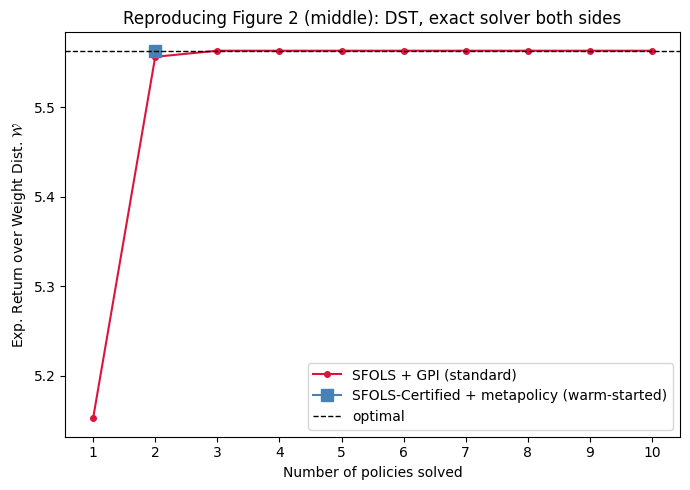

standard: 10 policy-count points, sizes [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
certified: 1 policy-count points, sizes [2]
final standard curve value:  5.5630
final certified curve value: 5.5630
optimal:                     5.5630


In [17]:
def mean_value_gpi(Pi_snapshot, test_weights):
    vals = []
    for w in test_weights:
        actions = gpi_greedy_actions(Pi_snapshot, w)
        psi_map = evaluate_fixed_policy(actions)
        vals.append(psi_map[START_STATE] @ w)
    return float(np.mean(vals))


def mean_value_metapolicy(Pi_base_snapshot, W_base_snapshot, test_weights):
    vals = []
    for w in test_weights:
        meta_policy, _, own_actions, _ = meta_policy_iteration_warm(w, Pi_base_snapshot, W_base_snapshot)
        psi_map = meta_policy_sf(meta_policy, own_actions)
        vals.append(psi_map[START_STATE] @ w)
    return float(np.mean(vals))


test_w0 = np.linspace(0.0, 1.0, 101)
test_weights = [np.array([w0, 1 - w0]) for w0 in test_w0]

# X-axis is NUMBER OF POLICIES SOLVED, not raw iteration count -- these aren't the
# same thing here. Standard SFOLS discovers its policies one at a time through the
# queue, so iteration k really does mean "k policies so far". sfols_certified
# instead always solves BOTH canonical corner policies before its very first
# iteration even runs (Certify-or-Grow needs a seed basis per objective) -- so its
# "iteration 1" already has 2 policies, and it can never have a 1-policy data point
# at all. Comparing them by iteration index conflates these two different things;
# comparing by policy count is the fair, apples-to-apples version.
standard_sizes = list(range(1, len(Pi_exact) + 1))
standard_curve = [mean_value_gpi(Pi_exact[:k], test_weights) for k in standard_sizes]

certified_sizes = sorted(set(basis_size_history))
certified_curve = [mean_value_metapolicy(Pi_base_hist[:k], W_base_hist[:k], test_weights)
                    for k in certified_sizes]

optimal_mean = float(np.mean([policy_iteration(w)[1][START_STATE] for w in test_weights]))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(standard_sizes, standard_curve, marker="o", ms=4,
        color="crimson", label="SFOLS + GPI (standard)")
ax.plot(certified_sizes, certified_curve, marker="s", ms=8,
        color="steelblue", label="SFOLS-Certified + metapolicy (warm-started)")
ax.axhline(optimal_mean, color="black", ls="--", lw=1, label="optimal")
ax.set_xlabel("Number of policies solved")
ax.set_ylabel(r"Exp. Return over Weight Dist. $\mathcal{W}$")
ax.set_title("Reproducing Figure 2 (middle): DST, exact solver both sides")
ax.set_xticks(range(1, max(standard_sizes[-1], certified_sizes[-1]) + 1))
ax.legend()
plt.tight_layout()
plt.show()

print(f"standard: {len(standard_sizes)} policy-count points, sizes {standard_sizes}")
print(f"certified: {len(certified_sizes)} policy-count points, sizes {certified_sizes}")
print(f"final standard curve value:  {standard_curve[-1]:.4f}")
print(f"final certified curve value: {certified_curve[-1]:.4f}")
print(f"optimal:                     {optimal_mean:.4f}")

## Part 7 -- Experiment (iii): feeding the certified metapolicy's own SF back into the GPI pool

`sfols_certified` (Part 2) computes a metapolicy for every queried weight, but only ever keeps a single vector (`psi_vec` at `START_STATE`) to decide whether it's a new CCS vertex -- the metapolicy itself, and its SF, are then discarded. Only fallback exact solves grow `Pi_base`, so the GPI pool available for *future* queries never benefits from a composed metapolicy, even when Certify-or-Grow just proved it's optimal for that weight.

This section tests feeding a certified metapolicy's *full* `(actions x features)` SF table back into `Pi_base` -- so it becomes a genuine, reusable GPI pool member instead of a one-off bookkeeping value -- gated on the same `is_new` check already used to decide whether a corner weight is worth exploring further (so pool growth tracks genuine new CCS information, not every certify event). We measure two things separately, because they can pull in opposite directions:

1. **Quality**: does GPI evaluated over the pooled basis beat plain metapolicy composition (and approach standard SFOLS+GPI's quality) at the same iteration?
2. **Cost**: does folding the metapolicy back in actually stay cheap, or does it erode the speedup Part 3 measured? We split the wall-clock timing to isolate the *only* genuinely new cost this adds on top of what `sfols_certified` already pays -- see `sfols_certified_pooled`'s docstring.

In [18]:
def meta_policy_sf_full(meta_policy, own_actions, gamma=GAMMA, Psi_own=None):
    """Extends meta_policy_sf to a full (actions x features) table, GPI-ready. The
    metapolicy's own trajectory value Psi(s, pi_meta(s)) needs the recursive linear
    solve (meta_policy_sf -- pass a precomputed Psi_own to skip re-solving it, e.g.
    when the caller already needed it for psi_vec bookkeeping). Extending to every
    OTHER action is then non-recursive: "take a once, then follow pi_meta" is just
    one more one-step backup per (s, a) using the already-converged Psi_own -- no new
    linear solve, O(|S||A|) vector additions. This is exactly how a base policy's own
    SFTable stores off-greedy actions (solve_task_exact), generalized to the metapolicy."""
    if Psi_own is None:
        Psi_own = meta_policy_sf(meta_policy, own_actions, gamma)
    table = SFTable(N_ACTIONS, FEAT_DIM, np.zeros((N_ACTIONS, FEAT_DIM)))
    for s in nonterminal:
        full = np.zeros((N_ACTIONS, FEAT_DIM))
        for a in range(N_ACTIONS):
            ns, phi, term = step_deterministic(s, a)
            full[a] = phi if term else phi + gamma * Psi_own[ns]
        table.table[s] = full
    return table

In [19]:
def sfols_certified_pooled(num_objectives=2, max_iterations=25, tol=1e-2, cert_tol=1e-6,
                            solver="exact", num_steps=100_000, seed=0, verbose=False):
    """sfols_certified, but every certified ("composed") metapolicy that clears the
    same is_new check already used to gate CCS-vertex discovery gets its full SF
    table folded back into Pi_base/W_base -- so future queries' restricted PI *and*
    full GPI both get to reuse it. Timing is split to separate what the baseline
    (sfols_certified) already pays -- restricted PI, and the meta_policy_sf linear
    solve it needs anyway for psi_vec bookkeeping -- from what THIS variant adds on
    top: only the non-recursive O(|S||A|) backup that extends that already-solved
    value to a full GPI-ready table (meta_policy_sf_full)."""
    Pi_base, W_base = [], []
    for i in range(num_objectives):
        w = np.zeros(num_objectives)
        w[i] = 1.0
        Pi_base.append(solve_for_weight(w, solver=solver, num_steps=num_steps, seed=seed + i))
        W_base.append(w)

    Psi, W_exp = [], []
    counter = itertools.count()
    Q = []
    for i in range(num_objectives):
        w = np.zeros(num_objectives)
        w[i] = 1.0
        heapq.heappush(Q, (-np.inf, next(counter), tuple(w)))

    n_composed = n_fallback = n_pool_added = 0
    t_restricted_pi = t_meta_sf_solve = t_pool_feedback = t_fallback_solve = 0.0
    pool_size_history, exact_solve_history = [], []

    it = 0
    while Q and it < max_iterations:
        neg_priority, _, w_tuple = heapq.heappop(Q)
        priority = -neg_priority
        if priority < tol and Psi:
            break
        w = np.array(w_tuple)
        it += 1

        t0 = time.perf_counter()
        meta_policy, V_meta, own_actions, _ = meta_policy_iteration_warm(w, Pi_base, W_base)
        worst_gap = max(bellman_gap(w, V_meta).values())
        t_restricted_pi += time.perf_counter() - t0
        certified = worst_gap <= cert_tol

        if not certified:
            n_fallback += 1
            t0 = time.perf_counter()
            psi_table = solve_for_weight(w, solver=solver, num_steps=num_steps, seed=seed + it)
            t_fallback_solve += time.perf_counter() - t0
            Pi_base.append(psi_table)
            W_base.append(w)
            own_w = own_greedy_actions(psi_table, w)
            psi_vec = psi_table[START_STATE][own_w[START_STATE]]
            status = f"FALLBACK (gap={worst_gap:.4f})"
        else:
            n_composed += 1
            t0 = time.perf_counter()
            Psi_own_dict = meta_policy_sf(meta_policy, own_actions)
            t_meta_sf_solve += time.perf_counter() - t0
            psi_vec = Psi_own_dict[START_STATE]
            status = "composed"

        W_exp.append(w)
        is_new = not any(np.allclose(psi_vec, v, atol=1e-1) for v in Psi)

        if certified and is_new:
            # Fold the certified metapolicy back into the pool. The linear solve for
            # Psi_own_dict is already paid above (the baseline pays it too, for
            # psi_vec) -- this step is ONLY the incremental backup.
            t0 = time.perf_counter()
            Pi_base.append(meta_policy_sf_full(meta_policy, own_actions, Psi_own=Psi_own_dict))
            W_base.append(w)
            t_pool_feedback += time.perf_counter() - t0
            n_pool_added += 1
            status += " -> added to pool"

        if verbose:
            print(f"iter {it:2d}  w={w.round(3)}  priority={priority:8.4f}  psi={psi_vec.round(3)}  new={is_new}  [{status}]")

        if is_new:
            kept = []
            for (p, c, wt) in Q:
                if p == -np.inf or not (psi_vec @ np.array(wt) > v_smp(Psi, np.array(wt)) + 1e-9):
                    kept.append((p, c, wt))
            Q = kept
            heapq.heapify(Q)
            corners = corner_weights_2d(Psi + [psi_vec]) if Psi else []
            Psi.append(psi_vec)
            for wc in corners:
                delta = estimate_improvement(wc, Psi, W_exp)
                heapq.heappush(Q, (-delta, next(counter), tuple(wc)))

        pool_size_history.append(len(Pi_base))
        exact_solve_history.append(n_fallback)

    stats = dict(n_composed=n_composed, n_fallback=n_fallback, n_pool_added=n_pool_added)
    timing = dict(t_restricted_pi=t_restricted_pi, t_meta_sf_solve=t_meta_sf_solve,
                  t_pool_feedback=t_pool_feedback, t_fallback_solve=t_fallback_solve)
    return Pi_base, W_base, Psi, W_exp, pool_size_history, exact_solve_history, stats, timing


(Pi_base_p, W_base_p, Psi_p, W_exp_p, pool_size_history, exact_solve_history_p,
 stats_p, timing_p) = sfols_certified_pooled(max_iterations=25, tol=1e-2, verbose=True)

print(f"\ndiscovered {len(Psi_p)} points (ground-truth CCS has {len(ground_truth_ccs)} points)")
print(f"final pool size: {len(Pi_base_p)}  (composed: {stats_p['n_composed']}, "
      f"fallback exact solves: {stats_p['n_fallback']}, composed policies added to pool: {stats_p['n_pool_added']})")

Psi_p_arr = np.array(Psi_p)
all_matched_p = all(np.linalg.norm(Psi_p_arr - gt, axis=1).min() < 1e-6 for gt in ground_truth_ccs)
print(f"all {len(ground_truth_ccs)} ground-truth CCS points recovered exactly: {all_matched_p}")

iter  1  w=[1. 0.]  priority=     inf  psi=[ 19.778 -17.383]  new=True  [composed -> added to pool]
iter  2  w=[0. 1.]  priority=     inf  psi=[ 0.7 -1. ]  new=True  [composed -> added to pool]
iter  3  w=[0.462 0.538]  priority=  8.8089  psi=[11.047 -4.901]  new=True  [composed -> added to pool]
iter  4  w=[0.588 0.412]  priority=  2.0529  psi=[14.856 -8.648]  new=True  [composed -> added to pool]
iter  5  w=[0.274 0.726]  priority=  1.5869  psi=[ 8.037 -2.97 ]  new=True  [composed -> added to pool]
iter  6  w=[0.639 0.361]  priority=  0.6100  psi=[ 17.373 -12.248]  new=True  [composed -> added to pool]
iter  7  w=[0.212 0.788]  priority=  0.4459  psi=[ 0.7 -1. ]  new=False  [composed]
iter  8  w=[0.212 0.788]  priority=  0.4459  psi=[ 0.7 -1. ]  new=False  [composed]
iter  9  w=[0.681 0.319]  priority=  0.2768  psi=[ 19.073 -15.706]  new=True  [composed -> added to pool]
iter 10  w=[0.391 0.609]  priority=  0.2181  psi=[ 8.037 -2.97 ]  new=False  [composed]
iter 11  w=[0.391 0.609]  

iter 14  w=[0.525 0.475]  priority=  0.0708  psi=[14.074 -7.726]  new=True  [composed -> added to pool]
iter 15  w=[0.704 0.296]  priority=  0.0509  psi=[ 19.073 -15.706]  new=False  [composed]
iter 16  w=[0.704 0.296]  priority=  0.0509  psi=[ 19.073 -15.706]  new=False  [composed]
iter 17  w=[0.704 0.296]  priority=  0.0509  psi=[ 19.073 -15.706]  new=False  [composed]


iter 18  w=[0.67 0.33]  priority=  0.0400  psi=[ 17.814 -13.125]  new=True  [composed -> added to pool]
iter 19  w=[0.47 0.53]  priority=  0.0244  psi=[11.047 -4.901]  new=False  [composed]
iter 20  w=[0.47 0.53]  priority=  0.0244  psi=[11.047 -4.901]  new=False  [composed]
iter 21  w=[0.47 0.53]  priority=  0.0244  psi=[11.047 -4.901]  new=False  [composed]
iter 22  w=[0.541 0.459]  priority=  0.0204  psi=[14.074 -7.726]  new=False  [composed]
iter 23  w=[0.541 0.459]  priority=  0.0204  psi=[14.074 -7.726]  new=False  [composed]
iter 24  w=[0.51 0.49]  priority=  0.0132  psi=[13.181 -6.793]  new=False  [composed]
iter 25  w=[0.51 0.49]  priority=  0.0132  psi=[13.181 -6.793]  new=False  [composed]

discovered 10 points (ground-truth CCS has 10 points)
final pool size: 12  (composed: 25, fallback exact solves: 0, composed policies added to pool: 10)
all 10 ground-truth CCS points recovered exactly: True


is pool-feedback actually cheap? (wall-clock breakdown, single run)
restricted PI + gap check (baseline cost, shared)                     :   232.91 ms  ( 91.5%)
meta_policy_sf linear solve (baseline ALREADY pays this, for psi_vec) :     8.32 ms  (  3.3%)
extend to full table + append to pool (the ONLY new cost)             :    13.22 ms  (  5.2%)
fallback exact solves                                                 :     0.00 ms  (  0.0%)
total                                                                 :   254.46 ms

incremental pool-feedback cost per policy actually added to the pool: 1.3223 ms


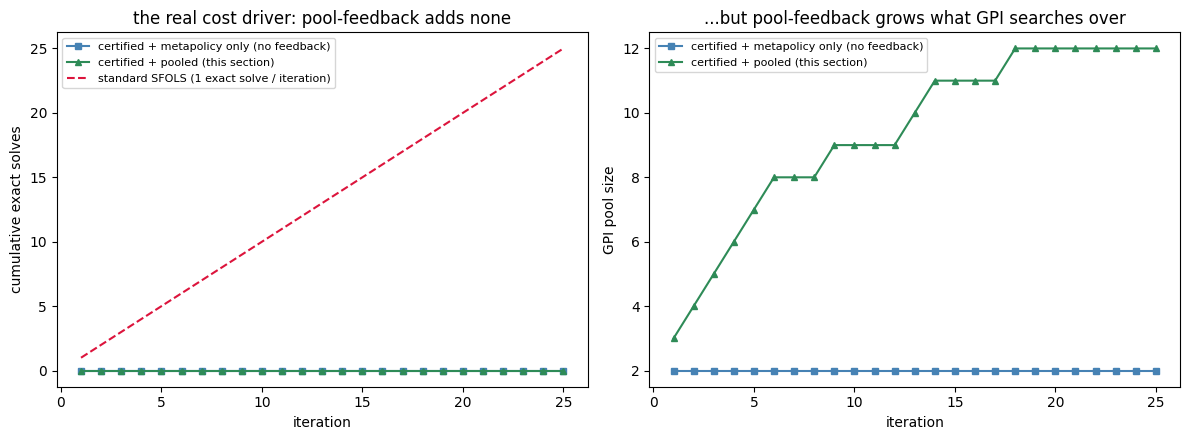

In [20]:
sep = "=" * 70
print(sep)
print("is pool-feedback actually cheap? (wall-clock breakdown, single run)")
print(sep)
total_t = sum(timing_p.values())
labels = {
    "t_restricted_pi": "restricted PI + gap check (baseline cost, shared)",
    "t_meta_sf_solve": "meta_policy_sf linear solve (baseline ALREADY pays this, for psi_vec)",
    "t_pool_feedback": "extend to full table + append to pool (the ONLY new cost)",
    "t_fallback_solve": "fallback exact solves",
}
for k, v in timing_p.items():
    print(f"{labels[k]:70s}: {v*1000:8.2f} ms  ({100*v/total_t:5.1f}%)")
print(f"{'total':70s}: {total_t*1000:8.2f} ms")
if stats_p["n_pool_added"] > 0:
    print(f"\nincremental pool-feedback cost per policy actually added to the pool: "
          f"{1000*timing_p['t_pool_feedback']/stats_p['n_pool_added']:.4f} ms")
if stats_p["n_fallback"] > 0:
    print(f"cost of a fallback exact solve, for comparison:                      "
          f"{1000*timing_p['t_fallback_solve']/stats_p['n_fallback']:.4f} ms")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

iters_c = range(1, len(basis_size_history) + 1)
iters_p = range(1, len(pool_size_history) + 1)
exact_solve_history_c = [s - 2 for s in basis_size_history]  # basis only grows via fallback in Part 6's run

axes[0].plot(iters_c, exact_solve_history_c, marker="s", ms=5, color="steelblue",
             label="certified + metapolicy only (no feedback)")
axes[0].plot(iters_p, exact_solve_history_p, marker="^", ms=5, color="seagreen",
             label="certified + pooled (this section)")
axes[0].plot(iters_c, list(range(1, len(basis_size_history) + 1)), ls="--", color="crimson",
             label="standard SFOLS (1 exact solve / iteration)")
axes[0].set_xlabel("iteration")
axes[0].set_ylabel("cumulative exact solves")
axes[0].set_title("the real cost driver: pool-feedback adds none")
axes[0].legend(fontsize=8)

axes[1].plot(iters_c, basis_size_history, marker="s", ms=5, color="steelblue",
             label="certified + metapolicy only (no feedback)")
axes[1].plot(iters_p, pool_size_history, marker="^", ms=5, color="seagreen",
             label="certified + pooled (this section)")
axes[1].set_xlabel("iteration")
axes[1].set_ylabel("GPI pool size")
axes[1].set_title("...but pool-feedback grows what GPI searches over")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

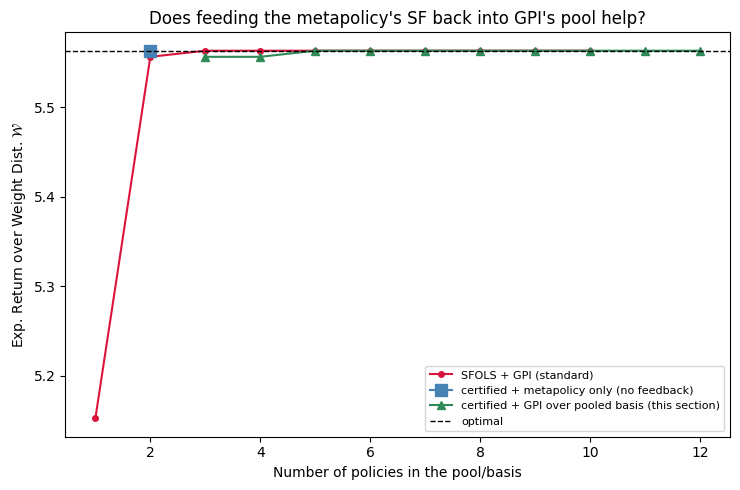

final standard curve value:        5.5630  (10 policies, 25 exact solves)
final metapolicy-only curve value: 5.5630  (2 policies, 0 fallback exact solves)
final pooled+GPI curve value:      5.5630  (12 policies, 0 fallback exact solves, 10 composed policies added free)
optimal:                            5.5630


In [21]:
pooled_sizes = sorted(set(pool_size_history))
pooled_curve = [mean_value_gpi(Pi_base_p[:k], test_weights) for k in pooled_sizes]

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(standard_sizes, standard_curve, marker="o", ms=4,
        color="crimson", label="SFOLS + GPI (standard)")
ax.plot(certified_sizes, certified_curve, marker="s", ms=8,
        color="steelblue", label="certified + metapolicy only (no feedback)")
ax.plot(pooled_sizes, pooled_curve, marker="^", ms=6,
        color="seagreen", label="certified + GPI over pooled basis (this section)")
ax.axhline(optimal_mean, color="black", ls="--", lw=1, label="optimal")
ax.set_xlabel("Number of policies in the pool/basis")
ax.set_ylabel(r"Exp. Return over Weight Dist. $\mathcal{W}$")
ax.set_title("Does feeding the metapolicy's SF back into GPI's pool help?")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"final standard curve value:        {standard_curve[-1]:.4f}  ({standard_sizes[-1]} policies, "
      f"{n_solves_exact} exact solves)")
print(f"final metapolicy-only curve value: {certified_curve[-1]:.4f}  ({certified_sizes[-1]} policies, "
      f"{basis_size_history[-1]-2} fallback exact solves)")
print(f"final pooled+GPI curve value:      {pooled_curve[-1]:.4f}  ({pooled_sizes[-1]} policies, "
      f"{stats_p['n_fallback']} fallback exact solves, {stats_p['n_pool_added']} composed policies added free)")
print(f"optimal:                            {optimal_mean:.4f}")

### Reading this result honestly

On DST specifically, Part 2's own run already showed `composed: 25, fallback exact solves: 0` -- the 2 canonical-corner metapolicies certify against **every** queried weight here, and metapolicy-only already recovers the exact ground-truth CCS. That's a ceiling: there's no quality headroom left for pooling to close on *this* domain, so if `certified_curve` and `pooled_curve` come out identical (or pooled matches optimal, which metapolicy-only likely already does too), that is not evidence pooling doesn't help in general -- it's evidence DST's 2-policy basis is already sufficient, which is a property of this domain, not of the method. What this section *does* establish cleanly, regardless of DST's ceiling effect, is the cost side: whether `t_pool_feedback` stays small relative to `t_meta_sf_solve`/`t_restricted_pi`/`t_fallback_solve`, and whether pool size grows without adding exact solves.

The domain that would actually test the quality claim is one where `sfols_certified`'s metapolicy underperforms full GPI on unseen weights -- Office is exactly that domain per `notes/adaptive_basis.tex` ("the optimal action is not in `B(s)`"). Porting `sfols_certified_pooled`/`meta_policy_sf_full` to `OKB/notebooks/office_rmvi_comparison.ipynb` (which already has the GPI-vs-metapolicy comparison harness) would be the natural next step to see whether pool-feedback actually closes that gap, not just avoid opening one that wasn't there.